In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import os
import zipfile

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

In [3]:
# Download dataset from alternative URL
url = "https://download.mlcc.google.com/mledu-datasets/cats_and_dogs_filtered.zip"

zip_path = tf.keras.utils.get_file(
    "cats_and_dogs_filtered.zip",
    origin=url,
    extract=False
)

# Extract dataset
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("./")

# Dataset paths
base_dir = "./cats_and_dogs_filtered"

train_dir = os.path.join(base_dir, "train")
val_dir = os.path.join(base_dir, "validation")

print("Dataset downloaded and extracted successfully!")
print("Training directory:", train_dir)
print("Validation directory:", val_dir)

68606236/68606236 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Dataset downloaded and extracted successfully!
Training directory: ./cats_and_dogs_filtered/train
Validation directory: ./cats_and_dogs_filtered/validation


In [4]:
img_size = (160, 160)
batch_size = 32

train_data = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=img_size,
    batch_size=batch_size,
    label_mode="binary"
)

val_data = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=img_size,
    batch_size=batch_size,
    label_mode="binary"
)

class_names = train_data.class_names
print("Classes:", class_names)

Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
Classes: ['cats', 'dogs']


In [5]:
# Normalize images for MobileNetV2
train_data = train_data.map(
    lambda x, y: (preprocess_input(x), y)
)

val_data = val_data.map(
    lambda x, y: (preprocess_input(x), y)
)

# Improve loading speed
train_data = train_data.prefetch(tf.data.AUTOTUNE)
val_data = val_data.prefetch(tf.data.AUTOTUNE)

In [6]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(160, 160, 3)
)

# Freeze pretrained layers
base_model.trainable = False

print("Pretrained model loaded")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Pretrained model loaded


In [7]:
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [8]:
history1 = model.fit(
    train_data,
    validation_data=val_data,
    epochs=3
)

Epoch 1/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 26s 224ms/step - accuracy: 0.9600 - loss: 0.0981 - val_accuracy: 0.9820 - val_loss: 0.0420
Epoch 2/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - accuracy: 0.9855 - loss: 0.0380 - val_accuracy: 0.9850 - val_loss: 0.0345
Epoch 3/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 51ms/step - accuracy: 0.9955 - loss: 0.0156 - val_accuracy: 0.9830 - val_loss: 0.0669


In [11]:
# Unfreeze pretrained model
base_model.trainable = True

# Freeze all except the last 20 layers
for layer in base_model.layers[:-20]:
    layer.trainable = False

# Keep Batch Normalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

# Compile model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Train and create history2
history2 = model.fit(
    train_data,
    validation_data=val_data,
    epochs=3
)

Epoch 1/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 24s 216ms/step - accuracy: 0.9895 - loss: 0.0395 - val_accuracy: 0.9830 - val_loss: 0.0553
Epoch 2/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 51ms/step - accuracy: 0.9895 - loss: 0.0298 - val_accuracy: 0.9820 - val_loss: 0.0435
Epoch 3/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - accuracy: 0.9965 - loss: 0.0069 - val_accuracy: 0.9720 - val_loss: 0.0880


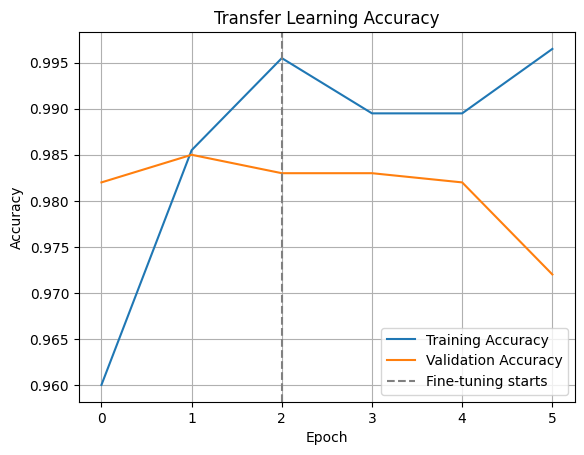

In [12]:
train_acc = history1.history["accuracy"] + history2.history["accuracy"]
val_acc = history1.history["val_accuracy"] + history2.history["val_accuracy"]

plt.plot(train_acc, label="Training Accuracy")
plt.plot(val_acc, label="Validation Accuracy")

plt.axvline(x=2, color="gray", linestyle="--",
            label="Fine-tuning starts")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Transfer Learning Accuracy")
plt.legend()
plt.grid()
plt.show()

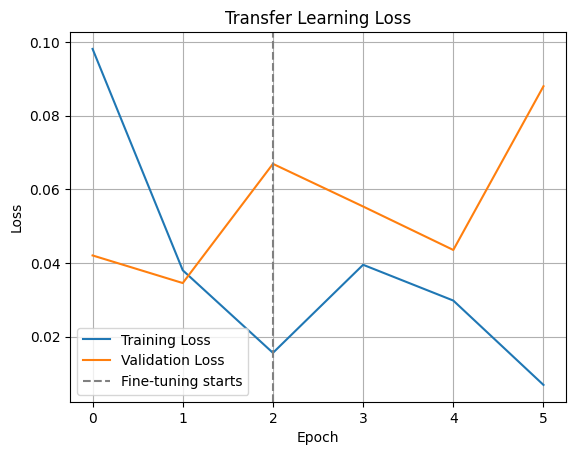

In [13]:
train_loss = history1.history["loss"] + history2.history["loss"]
val_loss = history1.history["val_loss"] + history2.history["val_loss"]

plt.plot(train_loss, label="Training Loss")
plt.plot(val_loss, label="Validation Loss")

plt.axvline(x=2, color="gray", linestyle="--",
            label="Fine-tuning starts")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Transfer Learning Loss")
plt.legend()
plt.grid()
plt.show()

In [14]:
loss, accuracy = model.evaluate(val_data)

print("Validation Loss:", round(loss, 4))
print("Validation Accuracy:", round(accuracy * 100, 2), "%")

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.9720 - loss: 0.0880
Validation Loss: 0.088
Validation Accuracy: 97.2 %


/tmp/ipykernel_625/2395500419.py:4: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  actual = int(labels[0].numpy())


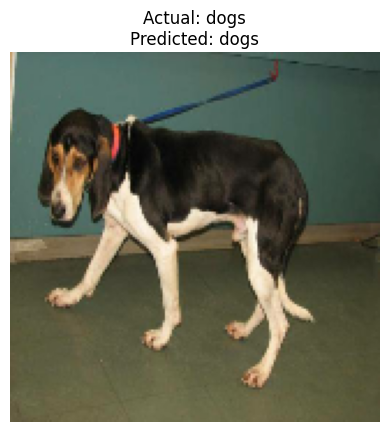

In [15]:
# Get one batch of validation images
for images, labels in val_data.take(1):
    image = images[0]
    actual = int(labels[0].numpy())

    prediction = model.predict(
        tf.expand_dims(image, axis=0),
        verbose=0
    )[0][0]

    predicted = 1 if prediction >= 0.5 else 0

    # Display image
    plt.imshow((image.numpy() + 1) / 2)
    plt.title(
        f"Actual: {class_names[actual]}\n"
        f"Predicted: {class_names[predicted]}"
    )
    plt.axis("off")
    plt.show()